### NHANES 3-Class Ordinal Classification 

This notebook implements an end-to-end clinical machine learning and deep learning pipeline to predict kidney damage stage from routine clinical biomarkers following THE 

**KDIGO (Kidney Disease: Improving Global Outcomes)** guidelines:


Class 0 (Normal): Urinary Albumin-to-Creatinine Ratio (ACR) < 30 mg/g


Class 1 (Microalbuminuria): 30 <= ACR < 300 mg/g


Class 2 (Macroalbuminuria): ACR >= 300 mg/g

## 1. env and etl

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import etl.etl_pipeline as ep
import preprocessing as pp
import model as m

SEED = 42
np.random.seed(SEED)

ingestion_df = ep.get_ingestion_summary("databases/nhanes_1st.db")
print("NHANES Raw Staged Tables Summary:")
display(ingestion_df)

db_stats = ep.verify_database_integrity("databases/nhanes_1st.db")
print(f"Total Rows in Harmonized Dataset: {db_stats['total_rows']:,}")
print("KDIGO Target Distribution in SQLite:", db_stats["kdigo_stages"])

NHANES Raw Staged Tables Summary:


,Table,Rows,Columns
0,Demographics,56893,6
1,HeartQuestions,54972,7
2,Body Measures,51221,5
3,Fasting,49452,3
4,Complete Blood Count,49452,6
5,Albumin_Creatinie,46355,4
6,Vitals,45946,10
7,Total Cholesterol,44013,3
8,HDL_Cholesterol,44013,3
9,Smoke,41045,4


Total Rows in Harmonized Dataset: 34,097
KDIGO Target Distribution in SQLite: {'None': 3926, '0.0': 26217, '1.0': 3265, '2.0': 689}


## 2. Load Harmonized Cohort from Database


Loaded raw dataset shape: (34097, 29)
Cleaned feature matrix: (30171, 21), Target array: (30171,)


,Stage,Count,Prevalence (%)
0,Normal,26217,86.89
1,Microalbuminuria,3265,10.82
2,Macroalbuminuria,689,2.28


C:\Users\mohan\AppData\Local\Temp\ipykernel_3056\2994296601.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=stage_df, x='Stage', y='Count', palette=['#3b82f6', '#f59e0b', '#ef4444'], ax=ax)


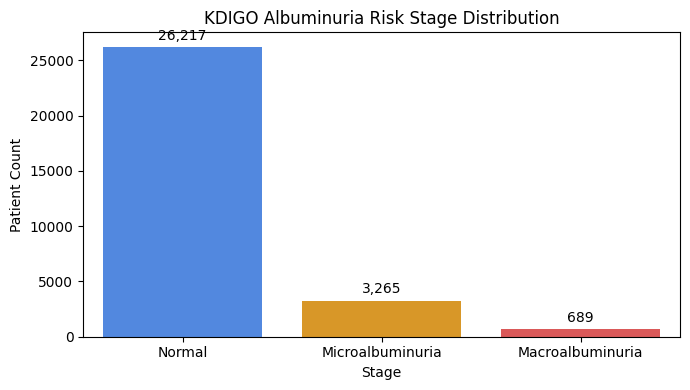

In [2]:
df_raw = pp.load_data_from_db("databases/nhanes_1st.db", "raw_dataset")
print(f"Loaded raw dataset shape: {df_raw.shape}")

X_raw, y = pp.extract_features_and_target(df_raw)
print(f"Cleaned feature matrix: {X_raw.shape}, Target array: {y.shape}")

stage_counts = y.value_counts().sort_index()
stage_df = pd.DataFrame({
    'Stage': [pp.STAGE_NAMES[i] for i in stage_counts.index],
    'Count': stage_counts.values,
    'Prevalence (%)': (stage_counts.values / len(y) * 100).round(2)
})
display(stage_df)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=stage_df, x='Stage', y='Count', palette=['#3b82f6', '#f59e0b', '#ef4444'], ax=ax)
ax.set_title("KDIGO Albuminuria Risk Stage Distribution")
ax.set_ylabel("Patient Count")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()

## 3. Feature Correlation Analysis & Clinical Redundancy Filtering


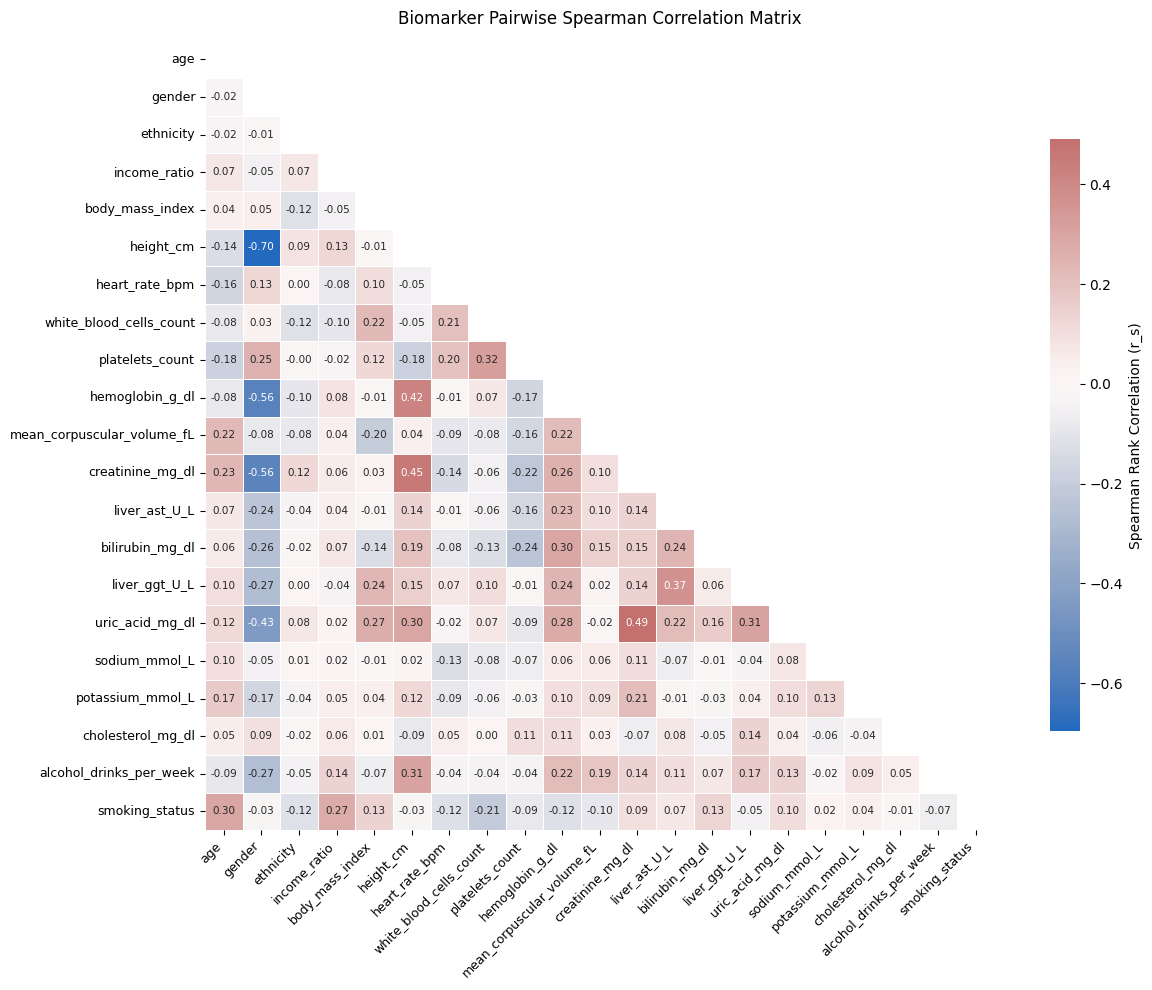

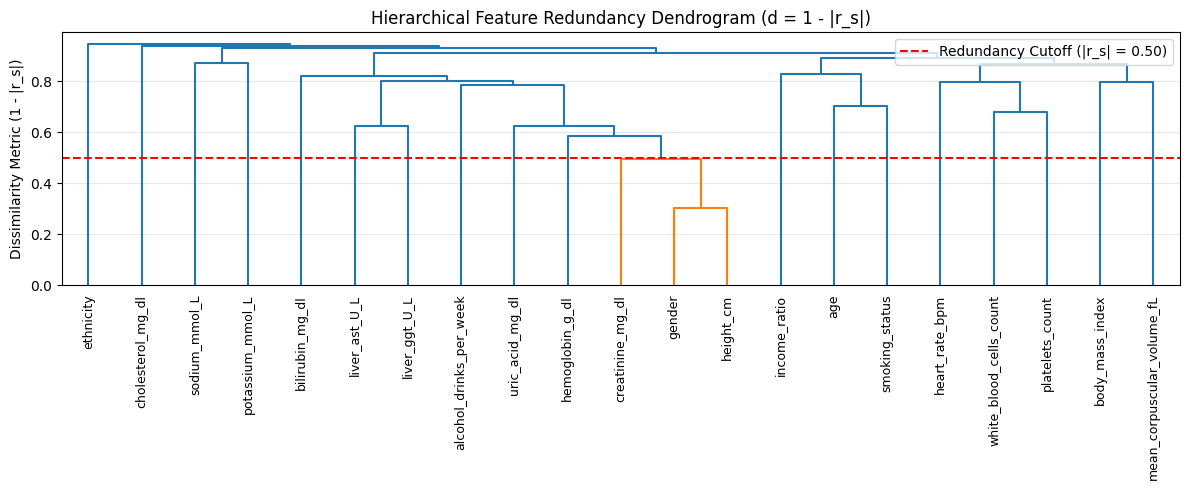

Initial features: 21 | Retained: 20 | Dropped: ['height_cm']


,pair,corr,action,kept,dropped,reason
0,gender vs height_cm,0.6965,DROPPED_height_cm,gender,height_cm,gender is protected clinical anchor
1,gender vs hemoglobin_g_dl,0.5631,KEPT_BOTH,"[gender, hemoglobin_g_dl]",None,Both are protected clinical anchors
2,gender vs creatinine_mg_dl,0.5569,KEPT_BOTH,"[gender, creatinine_mg_dl]",None,Both are protected clinical anchors


In [3]:
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage, dendrogram

corr_matrix = X_raw.corr(method='spearman')

plt.figure(figsize=(13, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='vlag', center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7.5}, square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.75, "label": "Spearman Rank Correlation (r_s)"})
plt.title("Biomarker Pairwise Spearman Correlation Matrix", fontsize=12, pad=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

dist_mat = 1.0 - corr_matrix.abs()
np.fill_diagonal(dist_mat.values, 0)
condensed_dist = squareform(dist_mat)
linkage_mat = linkage(condensed_dist, method='average')

plt.figure(figsize=(12, 5))
dendrogram(linkage_mat, labels=X_raw.columns.tolist(), leaf_rotation=90, leaf_font_size=9, color_threshold=0.50)
plt.axhline(y=0.50, color='red', linestyle='--', label='Redundancy Cutoff (|r_s| = 0.50)')
plt.title("Hierarchical Feature Redundancy Dendrogram (d = 1 - |r_s|)", fontsize=12)
plt.ylabel("Dissimilarity Metric (1 - |r_s|)")
plt.legend(loc='upper right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

corr_filter = pp.ClinicalCorrelationFilter(threshold=0.50)
corr_filter.fit(X_raw, y)
pruning_report = corr_filter.get_pruning_report()
print(f"Initial features: {X_raw.shape[1]} | Retained: {len(corr_filter.retained_features_)} | Dropped: {corr_filter.dropped_features_}")
display(pruning_report)

X_filtered = corr_filter.transform(X_raw)

## 4. Stratified Data Split & Preprocessing Pipeline
We perform an 80/20 stratified train/test split.
IterativeImputer  and StandardScaler

In [4]:
X_train, X_test, y_train, y_test = pp.split_data(X_filtered, y, test_size=0.20, random_state=SEED)
print(f"Training set: {X_train.shape[0]:,} samples | Testing set: {X_test.shape[0]:,} samples")

preprocessor, cont_cols, cat_cols = pp.build_preprocessor(
    feature_names=X_filtered.columns.tolist(),
    categorical_cols=pp.CATEGORICAL_FEATURES,
    max_iter=10,
    random_state=SEED
)

X_train_proc, X_test_proc, feature_names = pp.fit_transform_pipeline(preprocessor, X_train, X_test)
print(f"Processed feature matrix: {X_train_proc.shape[1]} features")
display(X_train_proc.head())

Training set: 24,136 samples | Testing set: 6,035 samples


Processed feature matrix: 29 features


,age,income_ratio,body_mass_index,heart_rate_bpm,white_blood_cells_count,platelets_count,hemoglobin_g_dl,mean_corpuscular_volume_fL,creatinine_mg_dl,liver_ast_U_L,...,ethnicity_1.0,ethnicity_2.0,ethnicity_3.0,ethnicity_4.0,ethnicity_6.0,ethnicity_7.0,smoking_status_1.0,smoking_status_2.0,smoking_status_3.0,smoking_status_nan
28850,0.866066,1.554843,0.316710,-1.002679,-0.560525,0.480784,-0.034457,0.962596,0.024844,-0.991414,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
14422,1.493558,-0.626287,-0.676353,-1.357676,-0.376183,-0.726853,-0.563716,-0.031886,-0.137035,-0.092898,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
30483,-0.445963,-1.625972,1.544247,-1.268927,-0.145756,0.731722,-0.696031,-0.048741,-0.298913,-0.542156,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1499,0.637887,-0.970334,-1.048752,-1.535175,0.038586,-0.726853,-0.365244,-0.267864,-0.433812,-0.028718,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
32837,-1.415724,-1.113146,0.633939,0.358144,0.336015,0.365223,-0.085115,-0.518871,-0.300621,-0.048368,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


## 5. Class Imbalance Handling
Macroalbuminuria comprises only 2.3% of adult NHANES participants

In [5]:
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight

unique_classes = np.unique(y_train)
class_weights_arr = compute_class_weight('balanced', classes=unique_classes, y=y_train)
class_weights_dict = dict(zip(unique_classes, class_weights_arr))
train_sample_weights = compute_sample_weight('balanced', y_train)

weight_df = pd.DataFrame({
    'Stage': [pp.STAGE_NAMES[i] for i in unique_classes],
    'Train Count': np.bincount(y_train),
    'Balanced Weight': class_weights_arr.round(3)
})
display(weight_df)

,Stage,Train Count,Balanced Weight
0,Normal,20973,0.384
1,Microalbuminuria,2612,3.080
2,Macroalbuminuria,551,14.601


## 6. Train 5 Traditional Machine Learning Models
We train 5 diverse classification algorithms:
1. Logistic Regression 
2. Random Forest 
3. Gradient Boosting 
4. XGBoost 
5. LightGBM 

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=120, max_depth=12, class_weight='balanced', random_state=SEED, n_jobs=1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=80, learning_rate=0.08, max_depth=4, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=80, learning_rate=0.08, max_depth=4, eval_metric='mlogloss', random_state=SEED, n_jobs=1),
    "LightGBM": LGBMClassifier(n_estimators=80, learning_rate=0.08, max_depth=4, class_weight='balanced', verbose=-1, random_state=SEED, n_jobs=1)
}

trained_models = {}
for name, clf in models.items():
    if name in ["Gradient Boosting", "XGBoost"]:
        clf.fit(X_train_proc, y_train, sample_weight=train_sample_weights)
    else:
        clf.fit(X_train_proc, y_train)
    trained_models[name] = clf
    print(f"Fitted: {name}")

Fitted: Logistic Regression


Fitted: Random Forest


Fitted: Gradient Boosting


Fitted: XGBoost


Fitted: LightGBM


## 7. Multi-Metric Baseline Evaluation & Top 2 Model Selection
We evaluate on the unseen test set ($N = 6,035$) using clinical metrics:
Accuracy, Balanced Accuracy, Macro F1, Weighted F1, Class 2 (Macro) Sensitivity, Cohen's Quadratic Weighted Kappa (kappa_w), and One-vs-Rest ROC-AUC.

In [7]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, cohen_kappa_score, roc_auc_score, confusion_matrix, classification_report
)

def evaluate_classifier(clf, X_test, y_test, name):
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
    weighted_f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    micro_recall = recall_score(y_test == 1, y_pred == 1, zero_division=0)
    macro_recall = recall_score(y_test == 2, y_pred == 2, zero_division=0)
    qwk = cohen_kappa_score(y_test, y_pred, weights='quadratic')
    roc_auc = roc_auc_score(y_test, y_prob, multi_class='ovr', average='macro')
    
    return {
        "Model": name,
        "Accuracy": acc,
        "Balanced_Acc": bal_acc,
        "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1,
        "Micro_Recall": micro_recall,
        "Macro_Recall": macro_recall,
        "Quadratic_Kappa": qwk,
        "Macro_AUC": roc_auc,
        "_y_pred": y_pred,
        "_y_prob": y_prob
    }

baseline_results = []
for name, clf in trained_models.items():
    res = evaluate_classifier(clf, X_test_proc, y_test, name)
    baseline_results.append(res)

baseline_df = pd.DataFrame(baseline_results).drop(columns=['_y_pred', '_y_prob'])
display(baseline_df.sort_values("Macro_F1", ascending=False).reset_index(drop=True))

top_2_names = baseline_df.sort_values("Macro_F1", ascending=False)["Model"].iloc[:2].tolist()
print(f"Top 2 Traditional ML Models selected for fine-tuning: {top_2_names}")

,Model,Accuracy,Balanced_Acc,Macro_F1,Weighted_F1,Micro_Recall,Macro_Recall,Quadratic_Kappa,Macro_AUC
0,Random Forest,0.851201,0.565282,0.600482,0.847980,0.350689,0.420290,0.404612,0.802652
1,Gradient Boosting,0.679702,0.580612,0.447365,0.734825,0.459418,0.572464,0.259320,0.763561
2,XGBoost,0.676553,0.587376,0.441179,0.732583,0.430322,0.623188,0.253132,0.759073
3,LightGBM,0.679039,0.577464,0.439383,0.734573,0.433384,0.586957,0.251632,0.762840
4,Logistic Regression,0.609279,0.541553,0.383251,0.685281,0.385911,0.601449,0.189895,0.721108


Top 2 Traditional ML Models selected for fine-tuning: ['Random Forest', 'Gradient Boosting']


## 8. Hyperparameter Fine-Tuning (Top 2 Models)
We fine-tune the top 2 traditional ML models using 3-fold Stratified Cross-Validation targeting Macro F1.

Tuning Random Forest...


  Best Params for Random Forest: {'max_depth': 12, 'n_estimators': 100}
Tuning Gradient Boosting...


  Best Params for Gradient Boosting: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 80}


,Model,Accuracy,Balanced_Acc,Macro_F1,Weighted_F1,Micro_Recall,Macro_Recall,Quadratic_Kappa,Macro_AUC
0,Random Forest (Tuned),0.854847,0.561976,0.599733,0.850419,0.350689,0.405797,0.406452,0.803081
1,Gradient Boosting (Tuned),0.669097,0.576426,0.438071,0.727660,0.467075,0.565217,0.250236,0.754613


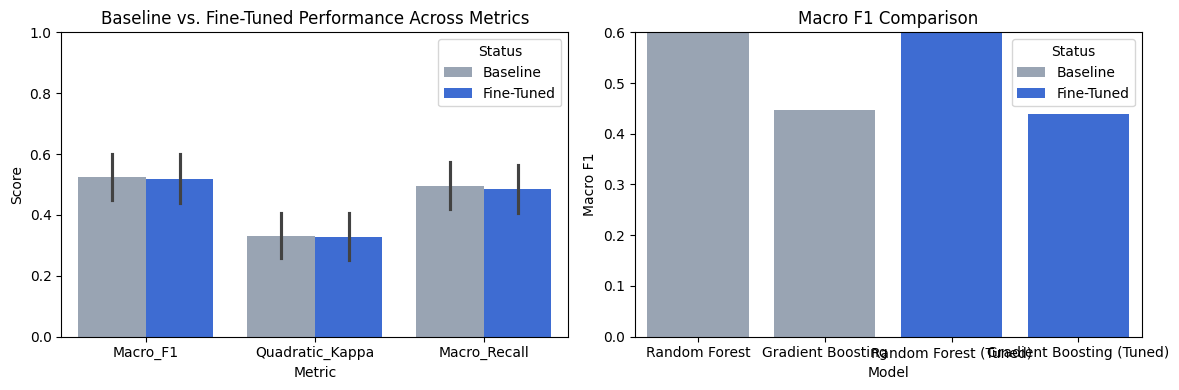

In [8]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
param_grids = {
    "Random Forest": {
        'n_estimators': [100, 150],
        'max_depth': [8, 12]
    },
    "LightGBM": {
        'n_estimators': [100],
        'learning_rate': [0.05, 0.1],
        'max_depth': [4, 6]
    },
    "XGBoost": {
        'n_estimators': [80],
        'learning_rate': [0.05, 0.1],
        'max_depth': [3, 4]
    },
    "Gradient Boosting": {
        'n_estimators': [80],
        'learning_rate': [0.05, 0.1],
        'max_depth': [3, 4]
    },
    "Logistic Regression": {
        'C': [0.5, 1.0]
    }
}

tuned_models = {}
for name in top_2_names:
    print(f"Tuning {name}...")
    base_clf = models[name]
    grid = GridSearchCV(base_clf, param_grids[name], scoring='f1_macro', cv=cv, n_jobs=1, verbose=0)
    if name in ["Gradient Boosting", "XGBoost"]:
        grid.fit(X_train_proc, y_train, sample_weight=train_sample_weights)
    else:
        grid.fit(X_train_proc, y_train)
    tuned_models[f"{name} (Tuned)"] = grid.best_estimator_
    print(f"  Best Params for {name}: {grid.best_params_}")

tuned_results = []
for name, clf in tuned_models.items():
    res = evaluate_classifier(clf, X_test_proc, y_test, name)
    tuned_results.append(res)

tuned_df = pd.DataFrame(tuned_results).drop(columns=['_y_pred', '_y_prob'])
display(tuned_df)

comp_df = pd.concat([
    baseline_df[baseline_df['Model'].isin(top_2_names)].copy().assign(Status='Baseline'),
    tuned_df.copy().assign(Status='Fine-Tuned')
], ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_data = comp_df.melt(id_vars=['Model', 'Status'], value_vars=['Macro_F1', 'Quadratic_Kappa', 'Macro_Recall'])
sns.barplot(data=plot_data, x='variable', y='value', hue='Status', ax=axes[0], palette=['#94a3b8', '#2563eb'])
axes[0].set_title("Baseline vs. Fine-Tuned Performance Across Metrics")
axes[0].set_ylabel("Score")
axes[0].set_xlabel("Metric")
axes[0].set_ylim(0, 1)

sns.barplot(data=comp_df, x='Model', y='Macro_F1', hue='Status', ax=axes[1], palette=['#94a3b8', '#2563eb'])
axes[1].set_title("Macro F1 Comparison")
axes[1].set_ylabel("Macro F1")
axes[1].set_ylim(0, 0.6)
plt.tight_layout()
plt.show()

## 9. PyTorch Deep Learning Approach: Ordinal MLP
We train a PyTorch Ordinal Multilayer Perceptron (Model 3)

Deep Learning Training Device: cuda


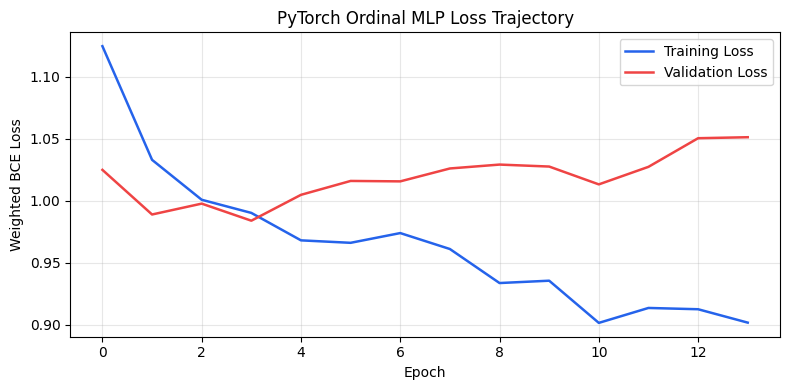

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

y_train_ord = m.make_ordinal_targets(y_train.values)
y_test_ord = m.make_ordinal_targets(y_test.values)
pos_weights = m.compute_ordinal_pos_weights(y_train_ord)

train_tensor_x = torch.tensor(X_train_proc.values, dtype=torch.float32)
train_tensor_y = torch.tensor(y_train_ord, dtype=torch.float32)
val_tensor_x = torch.tensor(X_test_proc.values, dtype=torch.float32)
val_tensor_y = torch.tensor(y_test_ord, dtype=torch.float32)

train_loader = DataLoader(TensorDataset(train_tensor_x, train_tensor_y), batch_size=128, shuffle=True)
val_loader = DataLoader(TensorDataset(val_tensor_x, val_tensor_y), batch_size=256, shuffle=False)

ordinal_net = m.OrdinalMLP(input_dim=X_train_proc.shape[1], dropout_rate=0.25)
ordinal_net, loss_hist = m.train_ordinal_model(
    ordinal_net, train_loader, val_loader, pos_weights=pos_weights,
    epochs=60, lr=0.001, patience=10, device=device
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(loss_hist['train_loss'], label='Training Loss', color='#2563eb', linewidth=1.8)
ax.plot(loss_hist['val_loss'], label='Validation Loss', color='#ef4444', linewidth=1.8)
ax.set_title("PyTorch Ordinal MLP Loss Trajectory")
ax.set_xlabel("Epoch")
ax.set_ylabel("Weighted BCE Loss")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

dl_preds, dl_probs = m.predict_ordinal(ordinal_net, X_test_proc.values, device=device)
dl_res = {
    "Model": "PyTorch Ordinal MLP",
    "Accuracy": accuracy_score(y_test, dl_preds),
    "Balanced_Acc": balanced_accuracy_score(y_test, dl_preds),
    "Macro_F1": f1_score(y_test, dl_preds, average='macro', zero_division=0),
    "Weighted_F1": f1_score(y_test, dl_preds, average='weighted', zero_division=0),
    "Micro_Recall": recall_score(y_test == 1, dl_preds == 1, zero_division=0),
    "Macro_Recall": recall_score(y_test == 2, dl_preds == 2, zero_division=0),
    "Quadratic_Kappa": cohen_kappa_score(y_test, dl_preds, weights='quadratic'),
    "Macro_AUC": roc_auc_score(y_test, dl_probs, multi_class='ovr', average='macro'),
    "_y_pred": dl_preds,
    "_y_prob": dl_probs
}

## 10. Model Comparison and Ordinal Error Analysis


,Model,Accuracy,Balanced_Acc,Macro_F1,Weighted_F1,Micro_Recall,Macro_Recall,Quadratic_Kappa,Macro_AUC
0,Random Forest,0.851201,0.565282,0.600482,0.847980,0.350689,0.420290,0.404612,0.802652
1,Random Forest (Tuned),0.854847,0.561976,0.599733,0.850419,0.350689,0.405797,0.406452,0.803081
2,Gradient Boosting,0.679702,0.580612,0.447365,0.734825,0.459418,0.572464,0.259320,0.763561
3,XGBoost,0.676553,0.587376,0.441179,0.732583,0.430322,0.623188,0.253132,0.759073
4,LightGBM,0.679039,0.577464,0.439383,0.734573,0.433384,0.586957,0.251632,0.762840
5,Gradient Boosting (Tuned),0.669097,0.576426,0.438071,0.727660,0.467075,0.565217,0.250236,0.754613
6,Logistic Regression,0.609279,0.541553,0.383251,0.685281,0.385911,0.601449,0.189895,0.721108
7,PyTorch Ordinal MLP,0.717647,0.543135,0.373062,0.756073,0.079632,0.753623,0.219067,0.694459


Top Performing Champion Model: Random Forest (Macro F1 = 0.6005, Kappa = 0.4046)


,Model,Exact Match (%),Adjacent Error (%),Severe 2-Stage Error (%),Mean Absolute Error
5,Random Forest (Tuned),85.484673,13.156587,1.358741,0.158741
1,Random Forest,85.120133,13.537697,1.342171,0.162220
2,Gradient Boosting,67.970174,27.058824,4.971002,0.370008
4,LightGBM,67.903894,26.362883,5.733223,0.378293
3,XGBoost,67.655344,26.528583,5.816073,0.381607
6,Gradient Boosting (Tuned),66.909693,27.622204,5.468103,0.385584
7,PyTorch Ordinal MLP,71.764706,14.598177,13.637117,0.418724
0,Logistic Regression,60.927920,29.047225,10.024855,0.490969


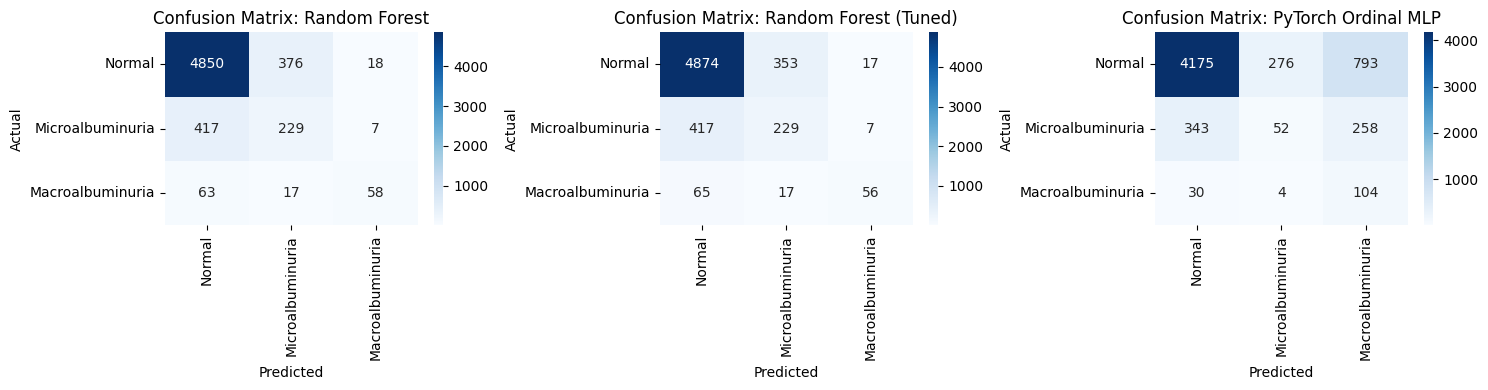

In [10]:
all_results_list = baseline_results + tuned_results + [dl_res]
master_df = pd.DataFrame(all_results_list).drop(columns=['_y_pred', '_y_prob']).sort_values("Macro_F1", ascending=False).reset_index(drop=True)
display(master_df)

champion_row = master_df.iloc[0]
champion_name = champion_row["Model"]
print(f"Top Performing Champion Model: {champion_name} (Macro F1 = {champion_row['Macro_F1']:.4f}, Kappa = {champion_row['Quadratic_Kappa']:.4f})")

def ordinal_error_profile(y_true, y_pred):
    diff = np.abs(np.asarray(y_true) - np.asarray(y_pred))
    return {
        "Exact Match (%)": np.mean(diff == 0) * 100,
        "Adjacent Error (%)": np.mean(diff == 1) * 100,
        "Severe 2-Stage Error (%)": np.mean(diff == 2) * 100,
        "Mean Absolute Error": np.mean(diff)
    }

error_rows = []
for res in all_results_list:
    err = ordinal_error_profile(y_test, res["_y_pred"])
    err["Model"] = res["Model"]
    error_rows.append(err)

display(pd.DataFrame(error_rows)[["Model", "Exact Match (%)", "Adjacent Error (%)", "Severe 2-Stage Error (%)", "Mean Absolute Error"]].sort_values("Mean Absolute Error"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
eval_models = [top_2_names[0], f"{top_2_names[0]} (Tuned)", "PyTorch Ordinal MLP"]
for i, m_name in enumerate(eval_models):
    m_dict = next(r for r in all_results_list if r["Model"] == m_name)
    cm = confusion_matrix(y_test, m_dict["_y_pred"])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=list(pp.STAGE_NAMES.values()), yticklabels=list(pp.STAGE_NAMES.values()))
    axes[i].set_title(f"Confusion Matrix: {m_name}")
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 11. Explainable AI (XAI) with SHAP
We interpret the best model using SHAP to visualize global feature importance and individual patient risk factor contributions.

C:\Users\mohan\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\mohan\AppData\Local\Temp\ipykernel_3056\3202518761.py:16: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_slice, X_test_proc.iloc[:200], show=False)


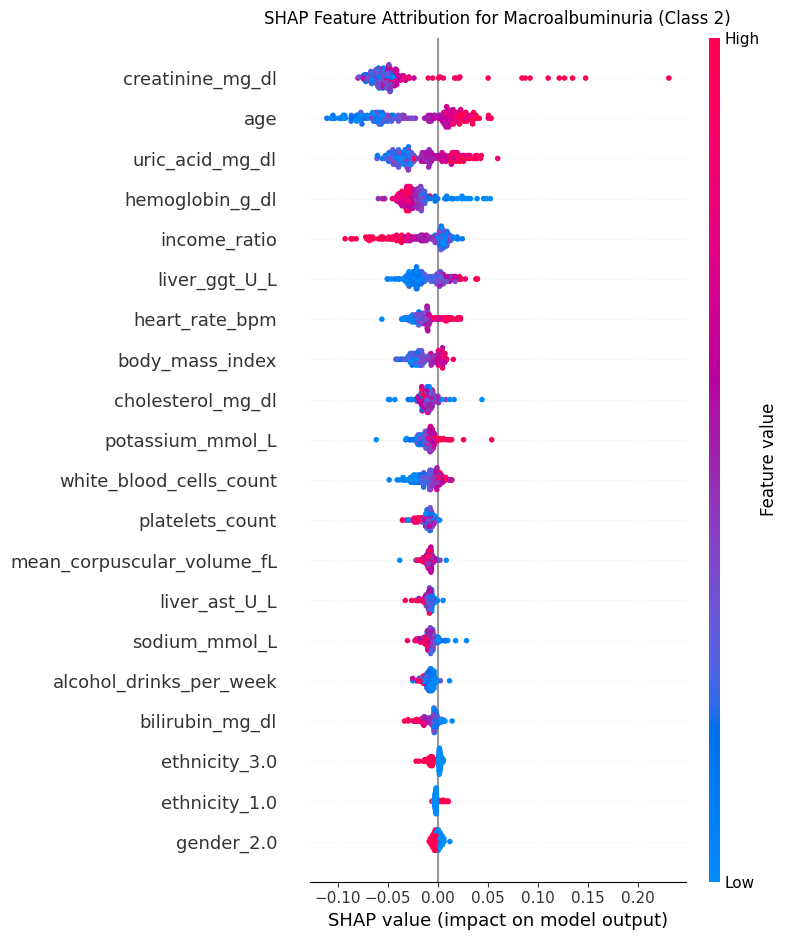

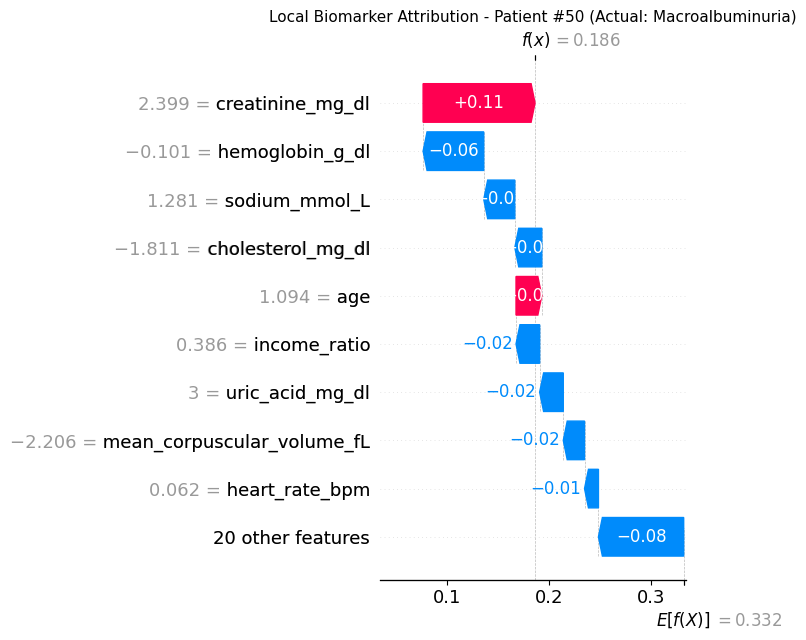

In [11]:
import shap

if "Tuned" in champion_name:
    best_clf = tuned_models[champion_name]
elif champion_name in trained_models:
    best_clf = trained_models[champion_name]
else:
    best_clf = trained_models[top_2_names[0]]

background = X_train_proc.sample(100, random_state=SEED)
explainer = shap.TreeExplainer(best_clf) if hasattr(best_clf, 'feature_importances_') else shap.Explainer(best_clf, background)
shap_values = explainer(X_test_proc.iloc[:200])

plt.figure(figsize=(10, 6))
shap_slice = shap_values[:, :, 2] if len(shap_values.shape) == 3 else shap_values
shap.summary_plot(shap_slice, X_test_proc.iloc[:200], show=False)
plt.title("SHAP Feature Attribution for Macroalbuminuria (Class 2)", fontsize=12, pad=10)
plt.tight_layout()
plt.show()

high_risk_indices = np.where(y_test.values == 2)[0]
sample_idx = high_risk_indices[0] if len(high_risk_indices) > 0 else 0
patient_shap = shap_values[sample_idx, :, 2] if len(shap_values.shape) == 3 else shap_values[sample_idx]

plt.figure(figsize=(9, 4))
shap.plots.waterfall(patient_shap, max_display=10, show=False)
plt.title(f"Local Biomarker Attribution - Patient #{sample_idx} (Actual: Macroalbuminuria)", fontsize=11)
plt.tight_layout()
plt.show()

## 12. Model Export

In [ ]:
import onnxruntime as ort

onnx_path = m.export_to_onnx(ordinal_net, input_dim=X_train_proc.shape[1], filepath="kidney_model.onnx")

ort_session = ort.InferenceSession(onnx_path)
test_input = X_test_proc.iloc[:5].values.astype(np.float32)
ort_preds = ort_session.run(None, {"input": test_input})[0]

print("Probabilities for first 5 patients:")
print(np.round(ort_preds, 4))

joblib.dump(preprocessor, "preprocessor.pkl")
joblib.dump(corr_filter.retained_features_, "retained_features.pkl")
joblib.dump(feature_names.tolist(), "processed_feature_names.pkl")
joblib.dump(best_clf, "champion_model.pkl")
joblib.dump(explainer, "shap_explainer.pkl")
joblib.dump(background, "shap_background.pkl")


ONNX Model successfully exported to: kidney_model.onnx
ONNX Runtime Verification Output (Probabilities for first 5 patients):
[[0.6596 0.1945 0.146 ]
 [0.6688 0.1952 0.1361]
 [0.2522 0.     0.7478]
 [0.2435 0.1574 0.5991]
 [0.7881 0.1901 0.0217]]


All pipeline artifacts saved successfully for web application deployment.
